# Assignment 2: Q1 & Q2

Q1 maps obesity by state. Q2 maps city elevations.

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

BASE = Path.cwd()
if not (BASE / "US_Data" / "us_state.shp").exists():
    BASE = BASE.parent
states = gpd.read_file(BASE / "US_Data" / "us_state.shp")
obesity = pd.read_csv(BASE / "other" / "National_Obesity_By_State.csv")

## Q1 - Obesity by state

The map highlights the highest and lowest values.

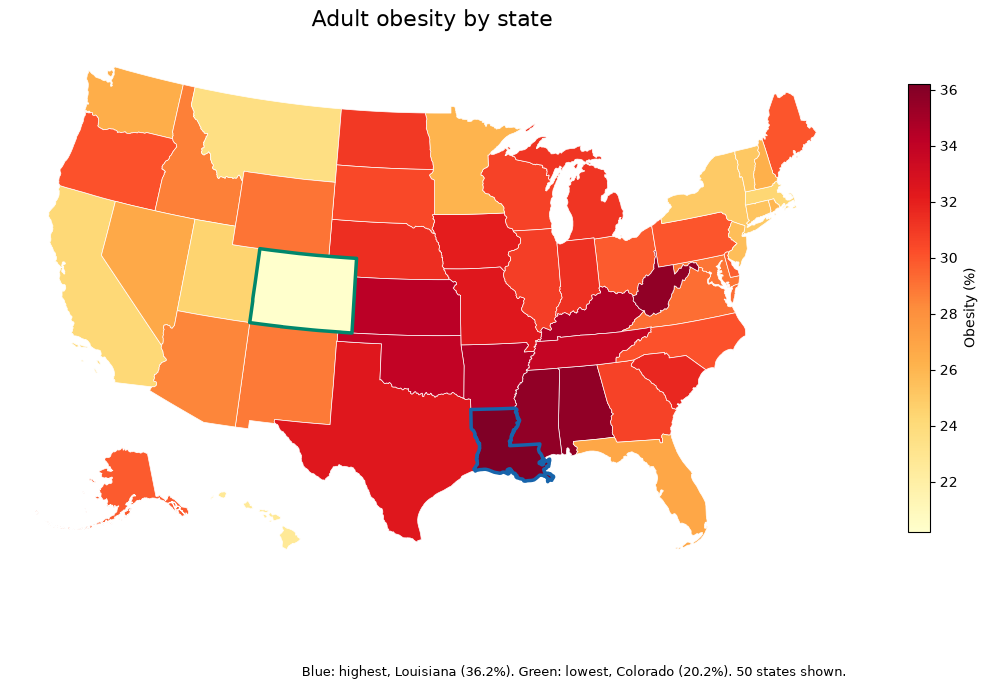

In [2]:
data = states.merge(obesity[["NAME", "Obesity"]], on="NAME", validate="one_to_one")
data = data.loc[~data["NAME"].isin(["District of Columbia", "Puerto Rico"])].copy()
high = data.loc[data["Obesity"].idxmax()]
low = data.loc[data["Obesity"].idxmin()]
norm = Normalize(data["Obesity"].min(), data["Obesity"].max())

fig, ax = plt.subplots(figsize=(12, 8))
main = data.loc[~data["NAME"].isin(["Alaska", "Hawaii"])].to_crs("EPSG:5070")
main.plot(column="Obesity", cmap="YlOrRd", norm=norm, edgecolor="white", linewidth=.5, ax=ax)

for name, color in [(high["NAME"], "#1764ab"), (low["NAME"], "#00876c")]:
    if name in main["NAME"].values:
        main.loc[main["NAME"].eq(name)].plot(ax=ax, facecolor="none", edgecolor=color, linewidth=2.5)

ak = ax.inset_axes([.02, .04, .20, .24])
hi = ax.inset_axes([.22, .04, .14, .12])
for inset, name, crs in [(ak, "Alaska", "EPSG:3338"), (hi, "Hawaii", "EPSG:3759")]:
    part = data.loc[data["NAME"].eq(name)].to_crs(crs)
    part.plot(column="Obesity", cmap="YlOrRd", norm=norm, edgecolor="white", linewidth=.5, ax=inset)
    for state, color in [(high["NAME"], "#1764ab"), (low["NAME"], "#00876c")]:
        if state in part["NAME"].values:
            part.loc[part["NAME"].eq(state)].plot(ax=inset, facecolor="none", edgecolor=color, linewidth=2.5)
    inset.set_axis_off()

ax.set_axis_off()
ax.set_title("Adult obesity by state", fontsize=16, pad=12)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="YlOrRd"), ax=ax, shrink=.7, label="Obesity (%)")
fig.text(.5, .04, f"Blue: highest, {high['NAME']} ({high['Obesity']:.1f}%). Green: lowest, {low['NAME']} ({low['Obesity']:.1f}%). 50 states shown.", ha="center", fontsize=9)
fig.subplots_adjust(left=.03, bottom=.1, right=.91, top=.9)
plt.show()

## Q2 - City elevations

Using the `usa_cities` dataset shown in the practice PDF (not included in US_Data.zip), each area takes its nearest city's elevation; Gaussian smoothing softens the boundaries. Higher elevations appear mostly in the interior West. The smoothed map is an estimate, not measured terrain.

Source: [geoplot usa_cities](https://github.com/ResidentMario/geoplot-data/blob/master/usa-cities.geojson). Elevations are in feet; the maps show the contiguous U.S.

In [ ]:
cities = gpd.read_file(BASE / "US_Data" / "usa-cities.geojson")
boundary = states.loc[~states["NAME"].isin(["Alaska", "Hawaii", "Puerto Rico", "District of Columbia"])].to_crs("EPSG:5070")
land = boundary.geometry.union_all()
points = cities.dropna(subset=["ELEV_IN_FT"]).to_crs("EPSG:5070")
points = points.loc[points.geometry.apply(land.covers)]
if points.empty:
    raise ValueError("No city points fall inside the contiguous U.S. boundaries.")

xmin, ymin, xmax, ymax = boundary.total_bounds
gx, gy = np.meshgrid(np.linspace(xmin, xmax, 420), np.linspace(ymin, ymax, 250))
coords = np.c_[points.geometry.x, points.geometry.y]
_, nearest = cKDTree(coords).query(np.c_[gx.ravel(), gy.ravel()])
voronoi = points["ELEV_IN_FT"].to_numpy(dtype=float)[nearest].reshape(gx.shape)
inside = shapely.contains_xy(land, gx, gy)
voronoi[~inside] = np.nan
smooth = gaussian_filter(np.nan_to_num(voronoi), 2) / np.maximum(gaussian_filter(inside.astype(float), 2), 1e-12)
smooth[~inside] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
extent = (xmin, xmax, ymin, ymax)
vmin, vmax = np.nanmin(voronoi), np.nanmax(voronoi)
for ax, surface, title in zip(axes, [voronoi, smooth], ["Voronoi", "Smoothed"]):
    image = ax.imshow(surface, origin="lower", extent=extent, cmap="terrain", vmin=vmin, vmax=vmax)
    boundary.boundary.plot(ax=ax, color="black", linewidth=.4)
    ax.scatter(points.geometry.x, points.geometry.y, s=2, color="black", alpha=.35)
    ax.set_title(title)
    ax.set_axis_off()
fig.colorbar(image, ax=axes, shrink=.7, label="Elevation (feet)")
fig.suptitle("City elevations, contiguous U.S.")
plt.show()